# **Exploratory Data Analysis (EDA)**



#### **Objective & Analysis Overview**
This notebook focuses on:

1.   Relationship Analysis
2.   Vendor Performance Analysis
3.   Pricing Analysis
4.   Profitability Analysis
5.   Inventory Efficiency Analysis
6.   Correlation Analysis
7.   Key Business Insights
8.   Recommendations




### Loaded Cleaned Dataset

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

DATA_PATH = Path("/content/drive/MyDrive/Procurement/cleaned_data")


In [4]:
purchases = pd.read_csv(DATA_PATH/'purchases_clean.csv')
purchase_prices = pd.read_csv(DATA_PATH/'purchase_prices_clean.csv')
vendor_invoice = pd.read_csv(DATA_PATH/'vendor_invoice_clean.csv')
vendor_sales_summary = pd.read_csv(DATA_PATH/'vendor_sales_summary_clean.csv')

### Relationship Analysis

#### Dataset Relationship

In [5]:
# Common Column
datasets = {
    "Purchases": purchases,
    "Purchase Prices": purchase_prices,
    "Vendor Invoice": vendor_invoice,
    "Vendor Sales Summary": vendor_sales_summary
}

from itertools import combinations

for (name1, df1), (name2, df2) in combinations(datasets.items(), 2):
    print(f"\n{name1} ↔ {name2}")
    print(set(df1.columns).intersection(df2.columns))


Purchases ↔ Purchase Prices
{'Brand', 'Size', 'Description', 'Classification', 'PurchasePrice', 'VendorNumber', 'VendorName'}

Purchases ↔ Vendor Invoice
{'Quantity', 'InvoiceDate', 'PODate', 'PayDate', 'VendorNumber', 'PONumber', 'Dollars', 'VendorName'}

Purchases ↔ Vendor Sales Summary
{'Brand', 'Description', 'PurchasePrice', 'VendorNumber', 'VendorName'}

Purchase Prices ↔ Vendor Invoice
{'VendorNumber', 'VendorName'}

Purchase Prices ↔ Vendor Sales Summary
{'Volume', 'Brand', 'Description', 'PurchasePrice', 'VendorNumber', 'VendorName'}

Vendor Invoice ↔ Vendor Sales Summary
{'VendorNumber', 'VendorName'}


#### **Relationship Findings**
* VendorNumber acts as the primary key across datasets.
Brand connects product-related datasets.
* PONumber links purchases and invoices.
* These relationships enable end-to-end vendor performance analysis.

### Vendor Performance Analysis
#### Top Vendors by Purchase Spend

In [18]:
top_vendors = (
    purchases.groupby("VendorName")["Dollars"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_vendors

,Dollars
VendorName,
Diageo North America Inc,50959796.85
Martignetti Companies,27861690.02
Jim Beam Brands Company,24203151.05
Pernod Ricard Usa,24124091.56
Bacardi Usa Inc,17624378.72
Constellation Brands Inc,15573917.90
Brown-Forman Corp,13529433.08
Ultra Beverage Company Llp,13210613.93
E & J Gallo Winery,12289608.09


#### Visualization

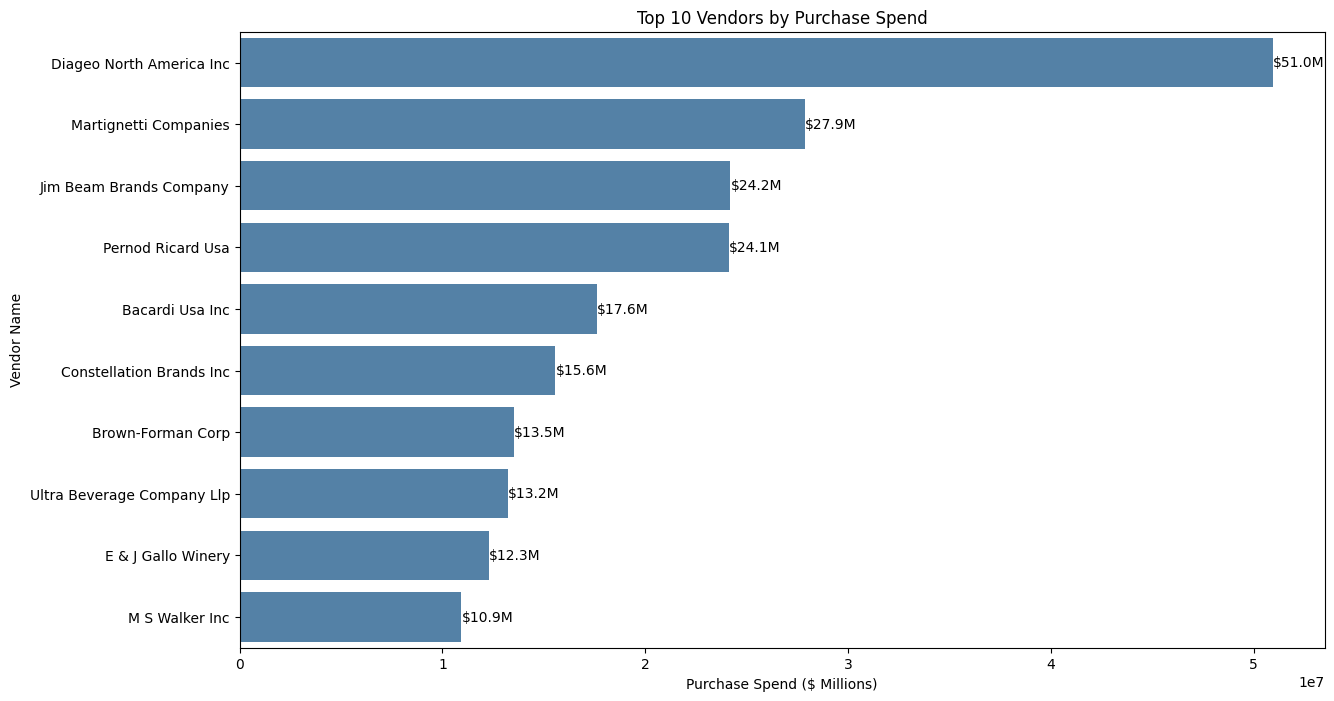

In [20]:
plt.figure(figsize=(14,8))

ax = sns.barplot(
    x=top_vendors.values,
    y=top_vendors.index,
    color='steelblue'
)

for i, value in enumerate(top_vendors.values):
    ax.text(
        value,
        i,
        f'${value/1_000_000:.1f}M',
        va='center'
    )

plt.title("Top 10 Vendors by Purchase Spend")
plt.xlabel("Purchase Spend ($ Millions)")
plt.ylabel("Vendor Name")
plt.show()

#### The top-performing vendors account for a significant share of procurement expenditure, indicating supplier concentration.

### Pricing Analysis
#### Purchase Price VS Actual Price

In [35]:
vendor_sales_summary[['PurchasePrice','ActualPrice']].describe()

,PurchasePrice,ActualPrice
count,10692.000000,10692.000000
mean,24.385303,35.643671
std,109.269375,148.246016
min,0.360000,0.490000
25%,6.840000,10.990000
50%,10.455000,15.990000
75%,19.482500,28.990000
max,5681.810000,7499.990000


In [22]:
vendor_sales_summary[['PurchasePrice','ActualPrice']].corr()

,PurchasePrice,ActualPrice
PurchasePrice,1.000000,0.997197
ActualPrice,0.997197,1.000000


#### **Pricing Insight**
Actual selling prices closely follow purchase prices, indicating a relatively consistent markup strategy across products.

#### Top Vendors by Gross Profit

In [27]:
top_profit = (
    vendor_sales_summary
    .groupby('VendorName')['GrossProfit']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
top_profit

,GrossProfit
VendorName,
Diageo North America Inc,17780038.12
Martignetti Companies,13098427.80
Constellation Brands Inc,8893216.33
Pernod Ricard Usa,8155452.61
Jim Beam Brands Company,7695470.11
Bacardi Usa Inc,7380987.07
E & J Gallo Winery,6264166.57
Brown-Forman Corp,4947178.52
Ultra Beverage Company Llp,4592032.17


### Visualization

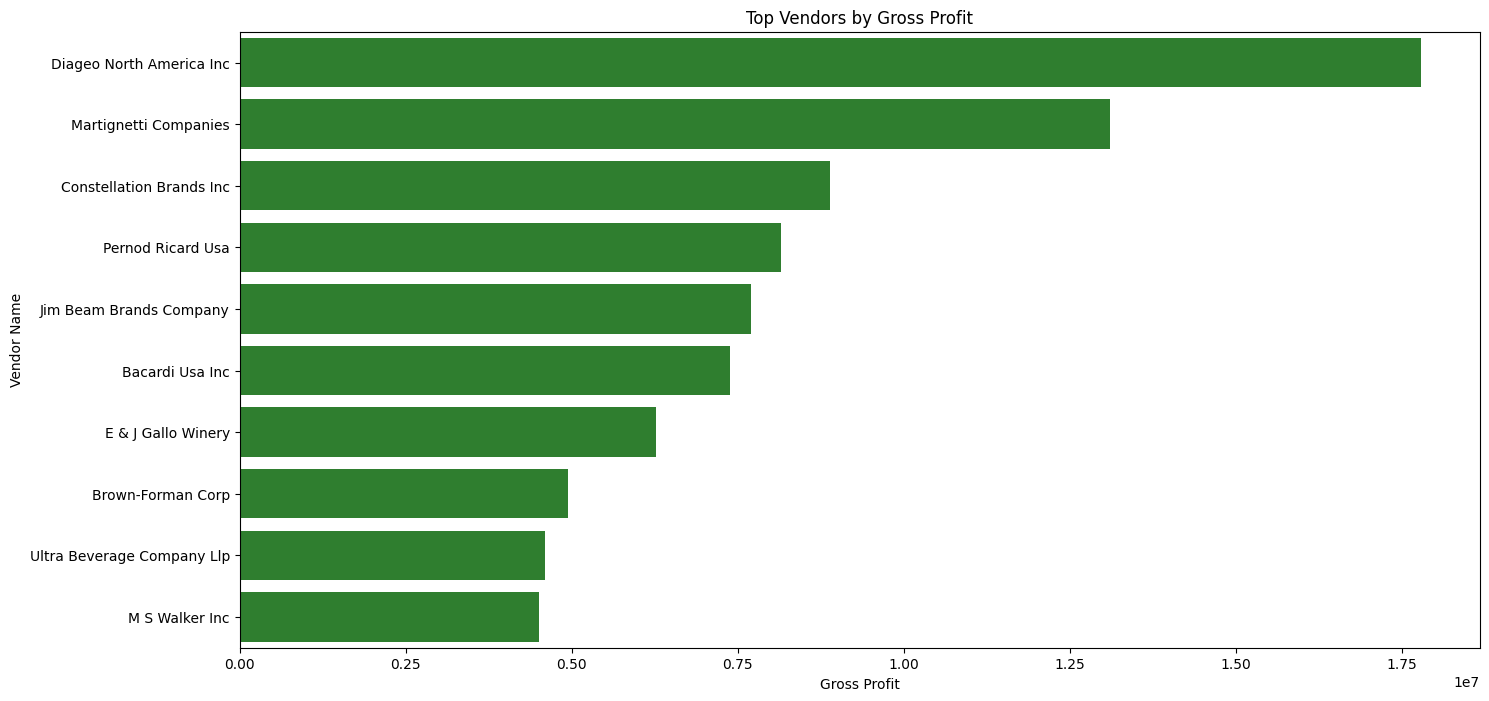

In [44]:
plt.figure(figsize=(16,8))

sns.barplot(
    x=top_profit.values,
    y=top_profit.index,
    color='forestgreen'
)

plt.title("Top Vendors by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Vendor Name")
plt.show()

### Sales-to-Purchase Ratio

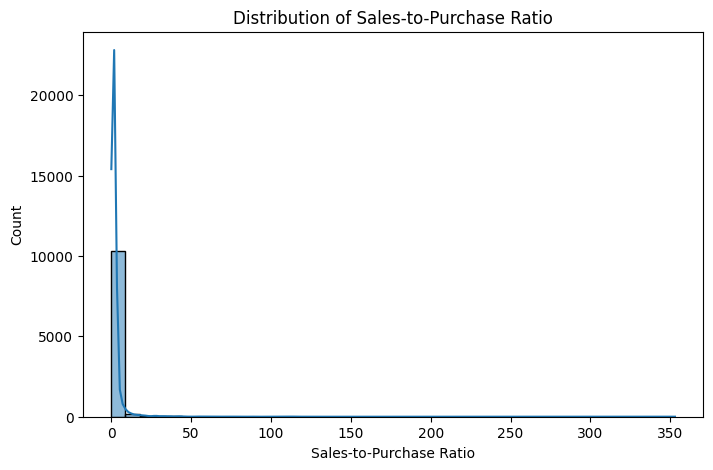

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(
    vendor_sales_summary['SalestoPurchaseRatio'],
    bins=40,
    kde=True
)

plt.title("Distribution of Sales-to-Purchase Ratio")
plt.xlabel("Sales-to-Purchase Ratio")
plt.show()

In [31]:
vendor_sales_summary[
    vendor_sales_summary['SalestoPurchaseRatio'] > 100
][[
    'VendorNumber',
    'Brand',
    'SalestoPurchaseRatio',
    'GrossProfit'
]].sort_values(
    'SalestoPurchaseRatio',
    ascending=False
).head(10)

,VendorNumber,Brand,SalestoPurchaseRatio,GrossProfit
10649,6213,4703,352.928571,2709.85
10641,9165,11209,252.994305,2212.51
10561,2555,5831,223.837079,4759.80
10625,12546,3406,219.705009,2357.64
10555,10754,5335,214.696533,4746.20
10651,4692,40583,164.924966,1201.57
10533,7153,23948,156.580119,3912.84
10639,9552,19526,153.457934,1431.58
10565,4425,25018,152.270309,3128.27
10275,9165,24101,122.483520,7813.82


#### Stock Turnover Interpretation

<Axes: xlabel='StockTurnover', ylabel='Count'>

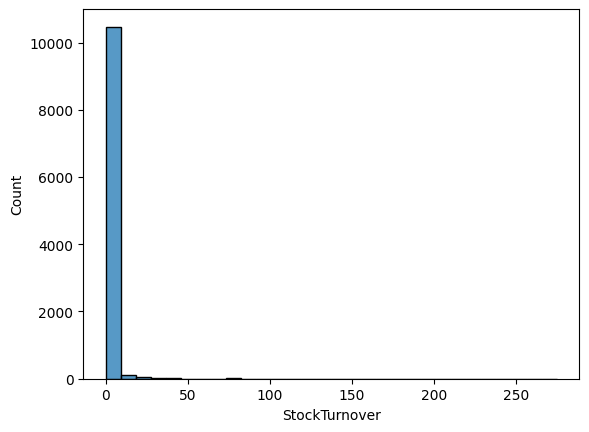

In [33]:
sns.histplot(
    vendor_sales_summary['StockTurnover'],
    bins=30
)

#### Observation
Most products exhibit relatively low stock turnover, while a smaller group demonstrates rapid inventory movement. High-turnover products may represent strong demand and efficient inventory management.

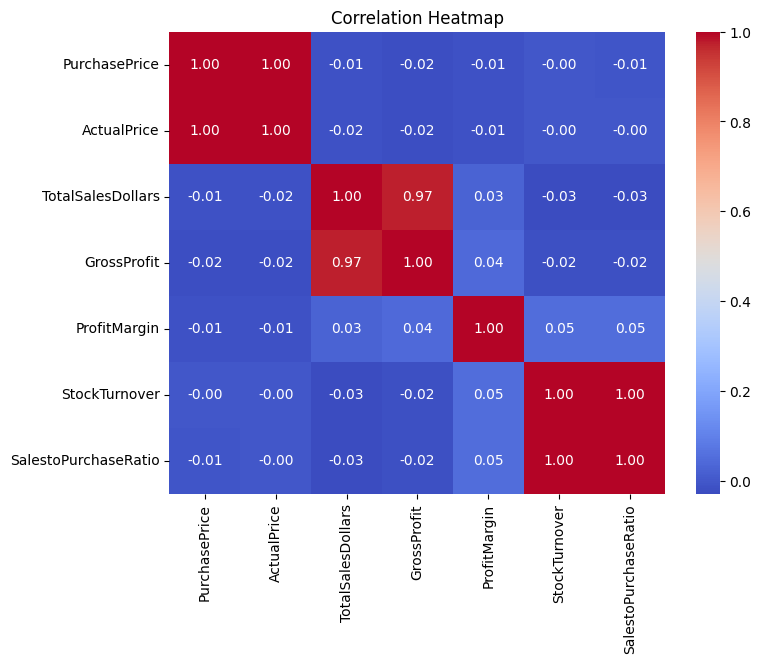

In [34]:
corr = vendor_sales_summary[[
    'PurchasePrice',
    'ActualPrice',
    'TotalSalesDollars',
    'GrossProfit',
    'ProfitMargin',
    'StockTurnover',
    'SalestoPurchaseRatio'
]].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

### **Correlation Analysis Findings**
 1. PurchasePrice and ActualPrice show a perfect positive correlation (1.00), indicating that products with higher procurement costs are consistently sold at higher prices.

 2. TotalSalesDollars and GrossProfit exhibit a very strong positive correlation (0.97), suggesting that revenue growth is a major driver of profitability.

 3. StockTurnover and SalestoPurchaseRatio have an almost perfect positive relationship (1.00), indicating that products with higher inventory turnover tend to achieve better sales efficiency.

4. ProfitMargin shows only weak correlations with other metrics, suggesting that profitability margins may be influenced by additional business factors beyond sales volume and pricing.

##**Key Business Insights**
1. Diageo North America Inc is the largest procurement partner, contributing more than $50M in purchase spend.

2. Revenue and profit are highly correlated (0.97), indicating that sales growth is the primary driver of profitability.

3. Products with higher stock turnover demonstrate stronger sales efficiency.

4. A small number of vendors account for a large proportion of procurement activity, suggesting supplier concentration risk.

5. Several products exhibit exceptionally high Sales-to-Purchase ratios, highlighting potential high-demand opportunities.

## **Recommendations**
1. Strengthen relationships with high-profit vendors.
Monitor supplier concentration and diversify where appropriate.

2. Increase focus on products demonstrating high inventory turnover.

3. Evaluate procurement strategy for low-performing vendors.

4. Investigate high-performing products for expansion opportunities.

## **Conclusion**
The analysis demonstrates that vendor performance is strongly influenced by sales volume, pricing strategy, and inventory efficiency. The findings provide actionable insights that can support procurement optimization, profitability enhancement, and strategic vendor management.